In [1]:
# imports
import numpy as np
import astropy as ap
from astropy.io import fits
import matplotlib.pyplot as plt


In [ ]:
BIT_DEPTH = 10
MAX_VAL = 2**BIT_DEPTH - 1
RANGE = MAX_VAL + 1

# Default JPEG-LS gradient thresholds, scaled for MAX_VAL (T.87 C.2.4.1.1)
_FACTOR = (min(MAX_VAL, 4095) + 128) >> 8
T1 = _FACTOR * (3 - 2) + 2
T2 = _FACTOR * (7 - 3) + 3
T3 = _FACTOR * (21 - 4) + 4

# Max length of a single Golomb codeword (bounds the unary part)
LIMIT = 2 * (BIT_DEPTH + max(8, BIT_DEPTH))

In [ ]:
# context modeling and determination helpers

# returns a, b, c, d
def get_causal_neighborhood(image, row, col, max_row, max_col):
    INIT_VAL = 2**(BIT_DEPTH - 1)

    if row == 0 and col == 0:
        return INIT_VAL, INIT_VAL, INIT_VAL, INIT_VAL

    if row == 0:
        a = image[row][col - 1]
        return a, a, a, a

    if col == 0:
        b = image[row - 1][col]
        d = image[row - 1][col + 1] if col + 1 < max_col else b
        return b, b, b, d

    a = image[row][col - 1]
    b = image[row - 1][col]
    c = image[row - 1][col - 1]

    if col + 1 < max_col:
        d = image[row - 1][col + 1]
    else:
        d = b

    return a, b, c, d

# returns d-b, b-c, c-a
def compute_local_gradients(a, b, c, d):
    return d - b, b - c, c - a

def quantize_gradient(g):
    if g < 0:
        if g <= -T3: return -4
        if g <= -T2: return -3
        if g <= -T1: return -2
        return -1
    elif g > 0:
        if g >= T3: return 4
        if g >= T2: return 3
        if g >= T1: return 2
        return 1
    return 0

def quantize_gradients(g1, g2, g3):
    return quantize_gradient(g1), quantize_gradient(g2), quantize_gradient(g3)

def merge_signs(q1, q2, q3):
    # if first non-zero quantized gradient is negative, flip signs of all
    if q1 < 0 or (q1 == 0 and q2 < 0) or (q1 == 0 and q2 == 0 and q3 < 0):
        return -q1, -q2, -q3, -1
    return q1, q2, q3, 1

def get_context_index(g1, g2, g3):
    q1, q2, q3 = quantize_gradients(g1, g2, g3)

    q1, q2, q3, sign = merge_signs(q1, q2, q3)
        
    # Flatten 3D coordinates into a single 1D index array (0 to 364)
    # Since q1, q2, q3 are now effectively non-negative or strictly bounded
    # this polynomial maps them perfectly to a unique integer.
    context_idx = (q1 * 81) + (q2 * 9) + q3
    
    return context_idx, sign

In [4]:
# edge detecting predictor
def predict_value(a, b, c):
    if c >= max(a, b):
        return min(a, b)
    elif c <= min(a, b):
        return max(a, b)
    else:
        return a + b - c

In [ ]:
N = [1] * 365
A = [4] * 365
B = [0] * 365
C = [0] * 365

RESET = 64
MIN_C, MAX_C = -128, 127

def reset_context_state():
    """
    Initializes the per-context statistics. Encoder and decoder must both
    call this before processing an image so their state stays in lockstep.
    """
    global N, A, B, C, Nn, RUN_INDEX
    init_a = max(2, (RANGE + 32) // 64)
    # Indices 365 and 366 are the run-interruption contexts (N and A only)
    N = [1] * 367
    A = [init_a] * 367
    B = [0] * 365
    C = [0] * 365
    Nn = [0] * 2  # count of negative errors per run-interruption context
    RUN_INDEX = 0

def apply_bias_correction(pred_x, context_idx, sign, max_val=MAX_VAL):
    """
    Adjusts the raw MED prediction using the context's historical bias.
    """
    # If the context polarity was flipped (sign == -1), invert the correction term
    correction = C[context_idx] if sign == 1 else -C[context_idx]

    # Apply correction and clamp to the valid pixel range
    pred_corr = pred_x + correction
    pred_corr = max(0, min(max_val, pred_corr))

    return pred_corr

def update_context_statistics(context_idx, error):
    """
    Updates the historical parameters A, B, C, and N for the current context.
    `error` must already be sign-aligned with the context and modulo-reduced.
    """
    # 1. Update basic running tallies
    B[context_idx] += error
    A[context_idx] += abs(error)

    # 2. Handle Context Reset / Downscaling (Forgetting factor for non-stationarity)
    if N[context_idx] == RESET:
        N[context_idx] >>= 1  # Halve the frequency count
        A[context_idx] >>= 1  # Halve the absolute error sum
        B[context_idx] >>= 1  # Halve the bias offset sum
    N[context_idx] += 1

    # 3. Re-estimate the Bias Correction value (C) for next time,
    # nudging C by one step and keeping B within (-N, 0]
    b_val = B[context_idx]
    n_val = N[context_idx]

    if b_val <= -n_val:
        # Systematic negative drift: decrease C
        b_val += n_val
        if C[context_idx] > MIN_C:
            C[context_idx] -= 1
        if b_val <= -n_val:
            b_val = -n_val + 1

    elif b_val > 0:
        # Systematic positive drift: increase C
        b_val -= n_val
        if C[context_idx] < MAX_C:
            C[context_idx] += 1
        if b_val > 0:
            b_val = 0

    B[context_idx] = b_val

In [ ]:
def reduce_prediction_error(error):
    """
    Folds the error into [-RANGE/2, RANGE/2) using modulo RANGE arithmetic.
    The decoder recovers the pixel by wrapping pred + error back into range.
    """
    if error < 0:
        error += RANGE
    if error >= (RANGE + 1) // 2:
        error -= RANGE
    return error


def map_prediction_error(error, k, context_idx):
    """
    Maps a signed prediction error into a non-negative integer (M).
    Interleaves positive and negative errors to optimize for Rice coding.
    """
    # When k == 0 and the context is biased negative, swap the interleaving
    # so the more probable sign gets the shorter code
    if k == 0 and 2 * B[context_idx] <= -N[context_idx]:
        if error >= 0:
            return 2 * error + 1
        return -2 * (error + 1)
    if error >= 0:
        return 2 * error
    return -2 * error - 1


def unmap_prediction_error(mapped_error, k, context_idx):
    """
    Inverse of map_prediction_error.
    """
    if k == 0 and 2 * B[context_idx] <= -N[context_idx]:
        if mapped_error & 1:
            return (mapped_error - 1) >> 1
        return -(mapped_error >> 1) - 1
    if mapped_error & 1:
        return -((mapped_error + 1) >> 1)
    return mapped_error >> 1


def estimate_golomb_parameter(A_val, N_val):
    """
    Dynamically finds the best shift value 'k' using the context statistics.
    Finds the smallest k such that (N << k) >= A.
    """
    k = 0
    # Keep shifting N left until it equals or exceeds the absolute error sum A
    while (N_val << k) < A_val:
        k += 1
    return k


class BitstreamWriter:
    """
    A simple helper class to pack arbitrary bit lengths into bytes.
    """
    def __init__(self):
        self.buffer = []
        self.current_byte = 0
        self.bit_count = 0

    def write_bits(self, value, num_bits):
        for i in range(num_bits - 1, -1, -1):
            bit = (value >> i) & 1
            self.current_byte = (self.current_byte << 1) | bit
            self.bit_count += 1
            
            if self.bit_count == 8:
                self.buffer.append(self.current_byte)
                self.current_byte = 0
                self.bit_count = 0

    def flush(self):
        # Pad remaining bits in the partial byte with zeros
        if self.bit_count > 0:
            self.current_byte <<= (8 - self.bit_count)
            self.buffer.append(self.current_byte)
            self.current_byte = 0
            self.bit_count = 0
        return bytes(self.buffer)


class BitstreamReader:
    """
    Reads bits back out of a byte string, MSB first.
    """
    def __init__(self, data):
        self.data = data
        self.byte_pos = 0
        self.bit_pos = 0

    def read_bit(self):
        bit = (self.data[self.byte_pos] >> (7 - self.bit_pos)) & 1
        self.bit_pos += 1
        if self.bit_pos == 8:
            self.bit_pos = 0
            self.byte_pos += 1
        return bit

    def read_bits(self, num_bits):
        value = 0
        for _ in range(num_bits):
            value = (value << 1) | self.read_bit()
        return value


def encode_rice_golomb(mapped_error, k, bitstream, limit=LIMIT):
    """
    Splits the mapped error into a unary quotient and binary remainder,
    then appends them to the bitstream.
    """
    # 1. Split into quotient (q) and remainder (r)
    quotient = mapped_error >> k
    remainder = mapped_error & ((1 << k) - 1)

    # Escape: very large errors would produce huge unary codes, so cap the
    # unary part and send the raw value instead (JPEG-LS limited-length code)
    max_quotient = limit - BIT_DEPTH - 1
    if quotient >= max_quotient:
        bitstream.write_bits((1 << max_quotient) - 1, max_quotient)
        bitstream.write_bits(0, 1)
        bitstream.write_bits(mapped_error - 1, BIT_DEPTH)
        return

    # 2. Write Unary Code for Quotient: 'q' number of 1s followed by a 0
    # (Note: Standard JPEG-LS uses 0s for unary; some variations use 1s)
    unary_value = (1 << quotient) - 1
    bitstream.write_bits(unary_value, quotient)
    bitstream.write_bits(0, 1) # The terminating 0 bit

    # 3. Write Binary Code for Remainder: exactly 'k' bits
    if k > 0:
        bitstream.write_bits(remainder, k)


def decode_rice_golomb(k, bitstream, limit=LIMIT):
    """
    Inverse of encode_rice_golomb.
    """
    max_quotient = limit - BIT_DEPTH - 1
    quotient = 0
    while bitstream.read_bit() == 1:
        quotient += 1

    if quotient >= max_quotient:
        return bitstream.read_bits(BIT_DEPTH) + 1

    return (quotient << k) | bitstream.read_bits(k)

In [ ]:
# --- RUN MODE (JPEG-LS T.87 A.7) ---
# Entered when all local gradients are zero (flat region). Encodes the length
# of the run of pixels equal to `a`, then the pixel that interrupts the run.

# Run-length segment sizes: each '1' bit means 2**J[RUN_INDEX] repeated pixels
J = [0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 3, 3,
     4, 4, 5, 5, 6, 6, 7, 7, 8, 9, 10, 11, 12, 13, 14, 15]

def encode_run_length(run_count, end_of_line, bitstream):
    global RUN_INDEX
    while run_count >= (1 << J[RUN_INDEX]):
        bitstream.write_bits(1, 1)
        run_count -= 1 << J[RUN_INDEX]
        if RUN_INDEX < 31:
            RUN_INDEX += 1

    if end_of_line:
        # Partial segment cut short by the end of the line
        if run_count > 0:
            bitstream.write_bits(1, 1)
    else:
        bitstream.write_bits(0, 1)
        bitstream.write_bits(run_count, J[RUN_INDEX])


def decode_run_length(remaining, bitstream):
    """
    Returns (run_count, end_of_line). `remaining` is the number of pixels
    left on the current line, starting at the first run pixel.
    """
    global RUN_INDEX
    run_count = 0
    while bitstream.read_bit() == 1:
        segment = 1 << J[RUN_INDEX]
        if remaining - run_count >= segment:
            run_count += segment
            if RUN_INDEX < 31:
                RUN_INDEX += 1
        else:
            run_count = remaining
        if run_count == remaining:
            return run_count, True

    run_count += bitstream.read_bits(J[RUN_INDEX])
    return run_count, False


def _run_interruption_k(ri_type):
    q = 365 + ri_type
    temp = A[q] + (N[q] >> 1) if ri_type else A[q]
    return estimate_golomb_parameter(temp, N[q])


def _update_run_interruption(ri_type, error, mapped_error):
    global RUN_INDEX
    q = 365 + ri_type
    if error < 0:
        Nn[ri_type] += 1
    A[q] += (mapped_error + 1 - ri_type) >> 1
    if N[q] == RESET:
        A[q] >>= 1
        N[q] >>= 1
        Nn[ri_type] >>= 1
    N[q] += 1
    if RUN_INDEX > 0:
        RUN_INDEX -= 1


def encode_run_interruption(pixel, a, b, bitstream):
    ri_type = 1 if a == b else 0
    pred = a if ri_type else b
    sign = -1 if (not ri_type and a > b) else 1
    error = reduce_prediction_error(sign * (pixel - pred))

    k = _run_interruption_k(ri_type)
    flip_threshold = 2 * Nn[ri_type] < N[365 + ri_type]
    if k == 0 and error > 0 and flip_threshold:
        map_bit = 1
    elif error < 0 and (not flip_threshold or k != 0):
        map_bit = 1
    else:
        map_bit = 0
    mapped_error = 2 * abs(error) - ri_type - map_bit

    encode_rice_golomb(mapped_error, k, bitstream, limit=LIMIT - J[RUN_INDEX] - 1)
    _update_run_interruption(ri_type, error, mapped_error)


def decode_run_interruption(a, b, bitstream):
    ri_type = 1 if a == b else 0
    pred = a if ri_type else b
    sign = -1 if (not ri_type and a > b) else 1

    k = _run_interruption_k(ri_type)
    mapped_error = decode_rice_golomb(k, bitstream, limit=LIMIT - J[RUN_INDEX] - 1)

    temp = mapped_error + ri_type
    map_bit = temp & 1
    magnitude = (temp + map_bit) >> 1
    # Same rule as the encoder: when k == 0 and negatives are rare, map=1 marks a positive error
    if k == 0 and 2 * Nn[ri_type] < N[365 + ri_type]:
        error = magnitude if map_bit else -magnitude
    else:
        error = -magnitude if map_bit else magnitude

    _update_run_interruption(ri_type, error, mapped_error)

    value = pred + sign * error
    if value < 0:
        value += RANGE
    elif value > MAX_VAL:
        value -= RANGE
    return value

In [ ]:
def compress_loco_i(image):
    """
    LOCO-I Image Compressor (regular + run mode).
    Takes a 2D numpy array (grayscale image) and returns a compressed byte stream.
    """
    max_row, max_col = image.shape
    bitstream = BitstreamWriter()

    # Pixels may be negative (e.g. calibrated FITS data), so shift them into
    # [0, MAX_VAL] and store the offset for the decoder
    offset = int(image.min())
    if int(image.max()) - offset > MAX_VAL:
        raise ValueError(f"pixel range exceeds {BIT_DEPTH} bits")
    if not -2**15 <= offset < 2**15:
        raise ValueError("pixel offset does not fit in 16 bits")
    # Plain Python ints: avoids int16 overflow and is much faster to index
    pixels = (image.astype(np.int64) - offset).tolist()

    # --- STEP 3: INITIALIZATION ---
    reset_context_state()

    # Encode metadata dimensions first so the decoder knows when to stop
    # Writing 16 bits for width and height allows images up to 65,535 x 65,535
    bitstream.write_bits(max_row, 16)
    bitstream.write_bits(max_col, 16)
    bitstream.write_bits(offset & 0xFFFF, 16)

    # --- RASTER SCAN ENGINE ---
    for row in range(max_row):
        col = 0
        while col < max_col:

            # 1. Neighborhood Fetching & Boundary Clamping
            a, b, c, d = get_causal_neighborhood(pixels, row, col, max_row, max_col)

            # 2. Structural Context Evaluation
            g1, g2, g3 = compute_local_gradients(a, b, c, d)

            # Flat neighborhood: switch to run mode
            if g1 == 0 and g2 == 0 and g3 == 0:
                run_count = 0
                while col + run_count < max_col and pixels[row][col + run_count] == a:
                    run_count += 1
                end_of_line = col + run_count == max_col
                encode_run_length(run_count, end_of_line, bitstream)
                col += run_count
                if not end_of_line:
                    ra, rb, _, _ = get_causal_neighborhood(pixels, row, col, max_row, max_col)
                    encode_run_interruption(pixels[row][col], ra, rb, bitstream)
                    col += 1
                continue

            context_idx, sign = get_context_index(g1, g2, g3)

            # 3. Median Edge Detection Prediction
            pred = predict_value(a, b, c)

            # 4. Bias Correction Alignment (Step 3a)
            pred_corr = apply_bias_correction(pred, context_idx, sign)

            # 5. Math Error Extraction, aligned with the context sign
            true_pixel = pixels[row][col]
            error = sign * (true_pixel - pred_corr)
            error = reduce_prediction_error(error)

            # 6. Entropy k-Parameter Estimation (Step 4b)
            k = estimate_golomb_parameter(A[context_idx], N[context_idx])

            # 7. Map to Non-Negative Domain (Step 4a)
            mapped_error = map_prediction_error(error, k, context_idx)

            # 8. Append Bits to Stream (Step 4c)
            encode_rice_golomb(mapped_error, k, bitstream)

            # 9. Update Context Memory for Next Time (Step 3b)
            update_context_statistics(context_idx, error)
            col += 1

    # Flush remaining bits out of the byte-packer buffer
    return bitstream.flush()

In [ ]:
def decompress_loco_i(compressed):
    """
    LOCO-I Image Decompressor (regular + run mode). Mirrors compress_loco_i exactly.
    """
    bitstream = BitstreamReader(compressed)
    max_row = bitstream.read_bits(16)
    max_col = bitstream.read_bits(16)
    offset = bitstream.read_bits(16)
    if offset >= 2**15:
        offset -= 2**16

    reset_context_state()
    pixels = [[0] * max_col for _ in range(max_row)]

    for row in range(max_row):
        col = 0
        while col < max_col:
            a, b, c, d = get_causal_neighborhood(pixels, row, col, max_row, max_col)
            g1, g2, g3 = compute_local_gradients(a, b, c, d)

            if g1 == 0 and g2 == 0 and g3 == 0:
                run_count, end_of_line = decode_run_length(max_col - col, bitstream)
                for i in range(run_count):
                    pixels[row][col + i] = a
                col += run_count
                if not end_of_line:
                    ra, rb, _, _ = get_causal_neighborhood(pixels, row, col, max_row, max_col)
                    pixels[row][col] = decode_run_interruption(ra, rb, bitstream)
                    col += 1
                continue

            context_idx, sign = get_context_index(g1, g2, g3)
            pred = predict_value(a, b, c)
            pred_corr = apply_bias_correction(pred, context_idx, sign)

            k = estimate_golomb_parameter(A[context_idx], N[context_idx])
            mapped_error = decode_rice_golomb(k, bitstream)
            error = unmap_prediction_error(mapped_error, k, context_idx)

            # Undo the modulo reduction by wrapping back into [0, MAX_VAL]
            value = pred_corr + sign * error
            if value < 0:
                value += RANGE
            elif value > MAX_VAL:
                value -= RANGE
            pixels[row][col] = value

            update_context_statistics(context_idx, error)
            col += 1

    return np.array(pixels, dtype=np.int64) + offset

In [8]:

hdul = fits.open("data/onc_l2a/hyb2_onc_20180824_062008_tvf_l2a.fit")
hdul.info()

Filename: data/onc_l2a/hyb2_onc_20180824_062008_tvf_l2a.fit
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      20   ()      
  1  ONC-LEVEL2a    1 ImageHDU       280   (1024, 1024)   int16   


In [9]:
# get image data
data = hdul[1].data

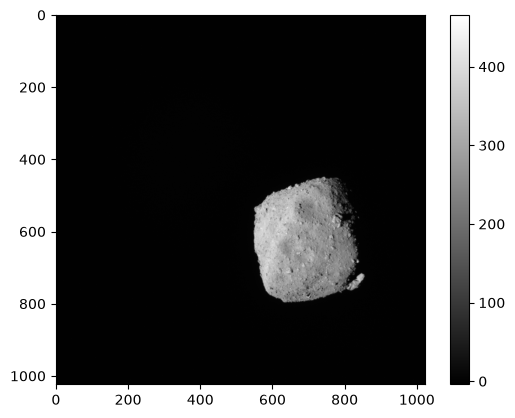

In [10]:
# Plot the image
plt.imshow(data, cmap="gray")
plt.colorbar()
plt.show()

In [ ]:
import os
import sys

def analyze_compression_performance(original_image, compressed_bytes):
    """
    Compares the size of the original uncompressed image matrix 
    versus the LOCO-I compressed byte payload.
    """
    # 1. Calculate Uncompressed Size
    # Size of the array as stored in memory (e.g. 2 bytes/pixel for int16)
    uncompressed_size_bytes = original_image.nbytes
    
    # 2. Calculate Compressed Size
    compressed_size_bytes = len(compressed_bytes)
    
    # 3. Calculate Advanced Efficiency Metrics
    # Compression Ratio: values > 1 means the file shrank (e.g., 2.5x smaller)
    compression_ratio = uncompressed_size_bytes / compressed_size_bytes
    
    # Space Saved: percentage reduction in storage size
    space_saved_percentage = (1 - (compressed_size_bytes / uncompressed_size_bytes)) * 100
    
    # Bits Per Pixel (bpp): compare against the storage and sensor bit depths. Lower is better.
    total_pixels = original_image.shape[0] * original_image.shape[1]
    bits_per_pixel = (compressed_size_bytes * 8) / total_pixels

    # --- PRINT THE PERFORMANCE REPORT ---
    print("=" * 45)
    print(" LOCO-I IMAGE COMPRESSION REPORT")
    print("=" * 45)
    print(f"Image Dimensions:     {original_image.shape[1]} x {original_image.shape[0]} pixels")
    print(f"Total Pixel Count:    {total_pixels:,} pixels\n")
    
    print(f"Uncompressed Size:    {uncompressed_size_bytes:,} bytes")
    print(f"Compressed Size:      {compressed_size_bytes:,} bytes\n")
    
    print(f"Compression Ratio:    {compression_ratio:.2f}x smaller")
    print(f"Space Saved:          {space_saved_percentage:.1f}% reduction")
    original_bpp = original_image.itemsize * 8
    print(f"Bitrate:              {bits_per_pixel:.2f} bits/pixel "
          f"(vs {original_bpp} bpp stored, {BIT_DEPTH} bpp sensor)")
    print("=" * 45)

# --- EXAMPLE USAGE ---
# # Assuming 'my_image' is your input numpy array:
# compressed_payload = compress_loco_i(my_image)
# analyze_compression_performance(my_image, compressed_payload)

In [ ]:
compressed = compress_loco_i(data)
analyze_compression_performance(data, compressed)

# Verify the round trip is lossless
decoded = decompress_loco_i(compressed)
assert np.array_equal(decoded, data), "decoded image does not match original"
print("Round trip OK: decoded image matches original exactly")

In [ ]:
import glob
import time

# Compress every image in the dataset and summarize
results = []
for path in sorted(glob.glob("data/onc_l2a/*.fit")):
    with fits.open(path) as f:
        img = f[1].data
    start = time.perf_counter()
    payload = compress_loco_i(img)
    assert np.array_equal(decompress_loco_i(payload), img), f"{path} not lossless"
    elapsed = time.perf_counter() - start
    results.append({
        "name": os.path.basename(path),
        "pixels": img.size,
        "raw": img.nbytes,
        "compressed": len(payload),
        "ratio": img.nbytes / len(payload),
        "bpp": len(payload) * 8 / img.size,
        "time": elapsed,
    })

print(f"{'Image':<40}{'Compressed':>12}{'Ratio':>8}{'bpp':>7}{'Time(s)':>9}")
for r in results:
    print(f"{r['name']:<40}{r['compressed']:>12,}{r['ratio']:>7.2f}x{r['bpp']:>7.3f}{r['time']:>9.1f}")

ratios = np.array([r["ratio"] for r in results])
bpps = np.array([r["bpp"] for r in results])
total_raw = sum(r["raw"] for r in results)
total_comp = sum(r["compressed"] for r in results)
total_pixels = sum(r["pixels"] for r in results)

print("=" * 76)
print(f"Images:                     {len(results)} (all round-trips lossless)")
print(f"Mean compression ratio:     {ratios.mean():.2f}x  (std {ratios.std():.2f}, "
      f"min {ratios.min():.2f}x, max {ratios.max():.2f}x)")
print(f"Aggregate ratio:            {total_raw / total_comp:.2f}x  "
      f"({total_raw:,} -> {total_comp:,} bytes)")
print(f"Mean bitrate:               {bpps.mean():.3f} bpp  (std {bpps.std():.3f})")
print(f"Aggregate bitrate:          {total_comp * 8 / total_pixels:.3f} bpp "
      f"(vs 16 bpp stored, {BIT_DEPTH} bpp sensor)")
print(f"Space saved (aggregate):    {(1 - total_comp / total_raw) * 100:.1f}%")